# C3 · Knowledge-graph cohort signals (live session)

Checks the graph built by `uv run anchorai kg load` and picks two thresholds: `ANCHOR_SHARE_THRESHOLD` in `anchorai/knowledge/signals.py` (when losing an instructor
counts as losing an *anchor*), and this notebook's `COHORT_FLAG`, which sizes the top cohorts and is not used by the app.

Open the Neo4j browser at http://localhost:7474 (user `neo4j`, password from `.env`) alongside this notebook.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from anchorai.discovery.scores import load_scores
from anchorai.knowledge import queries
from anchorai.knowledge.ego import ego_graph
from anchorai.knowledge.graph import neo4j_available, read
from anchorai.knowledge.signals import ANCHOR_SHARE_THRESHOLD, compute_kg_facts
from anchorai.scenario.tables import read_tables

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG, RES = Path("figures"), Path("results")
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

assert neo4j_available(), "Start Neo4j (docker compose up -d neo4j) and run `uv run anchorai kg load`"
tables = read_tables()
scores = load_scores().set_index("member_id")
members = tables["members"].set_index("member_id")
pd.DataFrame(read("MATCH (n) RETURN labels(n)[0] AS label, count(*) AS nodes ORDER BY label"))

,label,nodes
0,Class,18
1,Club,3
2,Event,2
3,Instructor,9
4,Member,4000
5,Offer,4


In [2]:
pd.DataFrame(read("""
MATCH (e:Event)-[:AFFECTS]->(x)
OPTIONAL MATCH (x)<-[:TAUGHT_BY]-(k:Class)
RETURN e.event_id AS event, e.type AS type, coalesce(x.name, x.class_id) AS target,
       collect(k.name) AS classes_taught, toString(e.week_start) AS week
"""))

,event,type,target,classes_taught,week
0,E001,instructor_left,Maya Chen,"[Core, Zumba]",2026-10-05
1,E002,class_cancelled,HIIT,[],2026-10-05


## 1. Lost anchor instructor

Share of a member's weekly class visits that were with instructors who have left (summed over all departed instructors, as in Stream A's
`true_churn.lost_instructor_share`). Paste this into the Neo4j browser
to see the affected cohort:

```cypher
MATCH p = (m:Member)-[:ATTENDS]->(:Class)-[:TAUGHT_BY]->(:Instructor)<-[:AFFECTS]-(:Event {type: 'instructor_left'})
RETURN p LIMIT 50
```

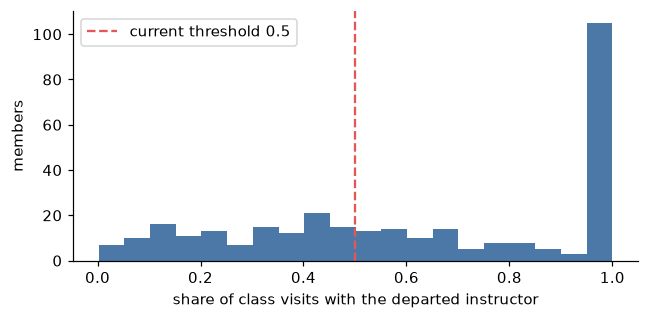

,0.25,0.40,0.50,0.60,0.75,1.00
members flagged,256,221,186,158,129,100


In [3]:
facts = compute_kg_facts()
share = facts["anchor_instructor_share"].dropna()
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(share, bins=20, color="#4c78a8")
ax.axvline(ANCHOR_SHARE_THRESHOLD, ls="--", color="#e45756", label=f"current threshold {ANCHOR_SHARE_THRESHOLD}")
ax.set_xlabel("share of class visits with the departed instructor"); ax.set_ylabel("members"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "c3_anchor_share.png"); plt.show()
pd.Series({t: int((share >= t).sum()) for t in (0.25, 0.4, 0.5, 0.6, 0.75, 1.0)}, name="members flagged").to_frame().T

## 2. Cancelled class

In [4]:
print(int(facts["class_cancelled"].sum()), "members attend the cancelled class")

170 members attend the cancelled class


## 3. Cohort risk

Mean churn probability of the people a member shares classes with. Worth keeping only if it says something the
member's own churn probability doesn't.

On real data cohort risk sits at 0.15-0.21 for everyone, so it is not shown as a graph signal. `COHORT_FLAG`
(a high cut-off: the counts below show how few members reach it) is only used to size the top cohorts for E7.

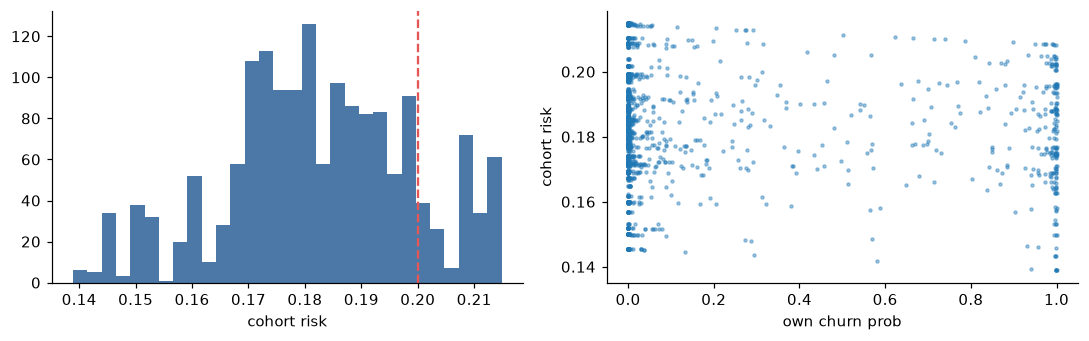

correlation with own churn prob: -0.04


,0.2,0.3,0.4,0.5
members flagged,238,0,0,0


In [5]:
COHORT_FLAG = 0.2
cohort = facts["cohort_risk"].dropna()
both = pd.DataFrame({"cohort_risk": cohort, "own_churn_prob": scores.loc[cohort.index, "churn_prob"]})
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(cohort, bins=30, color="#4c78a8")
axes[0].axvline(COHORT_FLAG, ls="--", color="#e45756")
axes[0].set_xlabel("cohort risk")
axes[1].scatter(both["own_churn_prob"], both["cohort_risk"], s=4, alpha=0.4)
axes[1].set_xlabel("own churn prob"); axes[1].set_ylabel("cohort risk")
fig.tight_layout(); fig.savefig(FIG / "c3_cohort_risk.png"); plt.show()
print("correlation with own churn prob:", round(both.corr().iloc[0, 1], 3))
pd.Series({t: int((cohort >= t).sum()) for t in (0.2, 0.3, 0.4, 0.5)}, name="members flagged").to_frame().T

## 4. Does a KG flag line up with churn? (E7 preview, training split)

`churn` is the real Kaggle label, which knows nothing about the synthetic gym events, so expect **no lift** here.
Stream A's `true_churn` table holds the scenario's event effect (`docs/SCENARIO.md`, "Gym events"); E7 measures
the KG signals against it, not against this label.

In [6]:
train = members["split"] == "train"
flags = facts.reindex(members.index)
rows = []
for name, mask in {
    "lost_anchor_instructor": flags["lost_anchor_instructor"].fillna(False).astype(bool),
    "class_cancelled": flags["class_cancelled"].fillna(False).astype(bool),
    f"cohort_risk >= {COHORT_FLAG}": flags["cohort_risk"].fillna(0) >= COHORT_FLAG,
}.items():
    m = mask & train
    rows.append({"signal": name, "members": int(mask.sum()), "train_churn": members.loc[m, "churn"].mean()})
base = members.loc[train, "churn"].mean()
signal_table = pd.DataFrame(rows).set_index("signal").assign(lift=lambda d: d["train_churn"] / base)
signal_table.round(3)

,members,train_churn,lift
signal,,,
lost_anchor_instructor,186,0.168,0.632
class_cancelled,170,0.191,0.722
cohort_risk >= 0.2,238,0.196,0.738


## 5. One member's neighbourhood (what Member 360 shows)

In [7]:
example = share.idxmax() if len(share) else members.index[0]
g = ego_graph(example)
print(example, "|", len(g.nodes), "nodes,", len(g.edges), "edges")
pd.DataFrame([n.data for n in g.nodes])[["type", "label"]]

M3560 | 5 nodes, 4 edges


,type,label
0,Member,M3560
1,Club,C2
2,Class,Zumba
3,Instructor,Maya Chen
4,Event,instructor_left


## 6. Decisions

- `ANCHOR_SHARE_THRESHOLD = 0.5`: flags 186 members (losing at least half their class visits)
- Cohort risk: kept as a fact for E7, not shown as a signal (no spread between members)
- E7: the KG signals show no lift on the Kaggle churn label (expected); E7 measures them against `true_churn` instead

In [8]:
signal_table.to_csv(RES / "c3_signal_churn.csv")